In [1]:
import os
print(os.listdir("/kaggle/input"))

['competitions']


In [2]:
import os
print(os.listdir("/kaggle/input/competitions"))

['aptos2019-blindness-detection']


In [3]:
import os
DATA_DIR = "/kaggle/input/competitions/aptos2019-blindness-detection"
print(os.listdir(DATA_DIR))

['sample_submission.csv', 'train_images', 'train.csv', 'test.csv', 'test_images']


In [5]:
import pandas as pd

df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
print(df.shape)
df.head()

(3662, 2)


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [6]:
# Cell: set image directory 
IMG_DIR = os.path.join(DATA_DIR, "train_images")
print(len(os.listdir(IMG_DIR)), "training images found")

3662 training images found


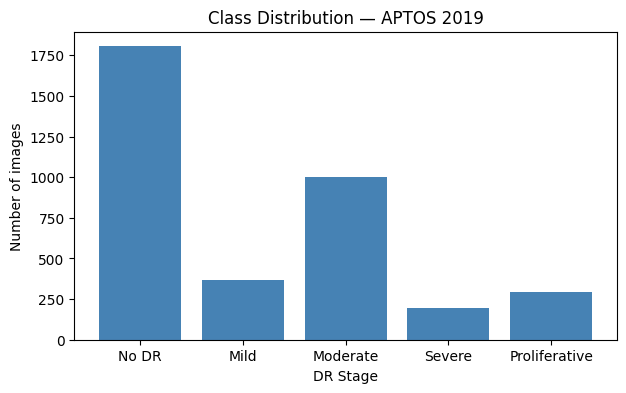

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64
diagnosis
0    49.3
1    10.1
2    27.3
3     5.3
4     8.1
Name: count, dtype: float64


In [7]:
# Cell: class distribution — evidence of imbalance
import matplotlib.pyplot as plt

LABELS = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}
counts = df["diagnosis"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar([LABELS[i] for i in counts.index], counts.values, color="steelblue")
plt.title("Class Distribution — APTOS 2019")
plt.ylabel("Number of images")
plt.xlabel("DR Stage")
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")  # save for report
plt.show()

print(counts)
print((counts / len(df) * 100).round(1))

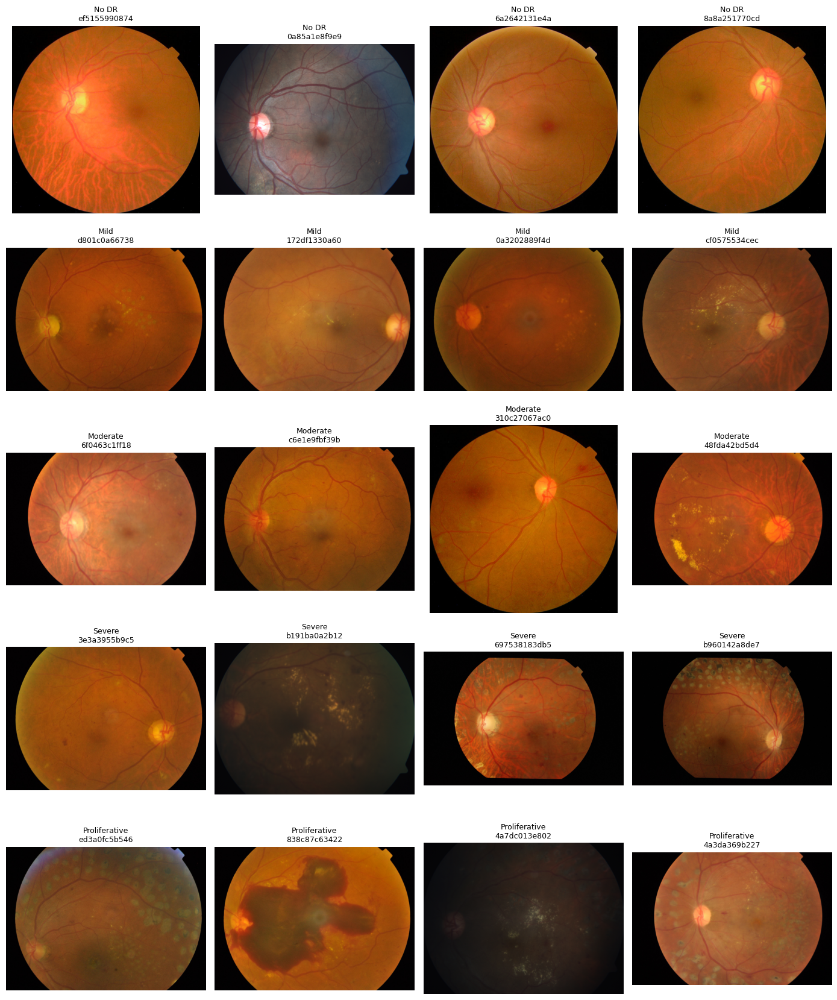

In [8]:
# Cell: sample images per class — visual evidence for the report
import cv2

fig, axes = plt.subplots(5, 4, figsize=(14, 17))
for cls in range(5):
    samples = df[df["diagnosis"] == cls].sample(4, random_state=42)
    for j, (_, row) in enumerate(samples.iterrows()):
        img_path = os.path.join(IMG_DIR, row["id_code"] + ".png")
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[cls, j].imshow(img)
        axes[cls, j].set_title(f"{LABELS[cls]}\n{row['id_code']}", fontsize=9)
        axes[cls, j].axis("off")

plt.tight_layout()
plt.savefig("sample_images_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Cell: image size / aspect ratio check — justifies resizing later
import random

sizes = []
for f in random.sample(list(df["id_code"]), 200):
    img_path = os.path.join(IMG_DIR, f + ".png")
    h, w = cv2.imread(img_path).shape[:2]
    sizes.append((h, w))

size_df = pd.DataFrame(sizes, columns=["height", "width"])
print(size_df.describe())

            height        width
count   200.000000   200.000000
mean   1462.905000  1926.825000
std     518.268363   856.001746
min     614.000000   819.000000
25%    1050.000000  1050.000000
50%    1536.000000  2048.000000
75%    1791.500000  2459.000000
max    2848.000000  4288.000000


In [10]:
from sklearn.model_selection import train_test_split

SEED = 42

# 70% train, 15% validation, 15% test — stratified by class
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["diagnosis"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["diagnosis"], random_state=SEED
)

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name}: {len(part)} images")
    dist = (part["diagnosis"].value_counts(normalize=True).sort_index() * 100).round(1)
    print(dist.to_dict(), "\n")

Train: 2563 images
{0: 49.3, 1: 10.1, 2: 27.3, 3: 5.3, 4: 8.1} 

Validation: 549 images
{0: 49.4, 1: 10.0, 2: 27.3, 3: 5.3, 4: 8.0} 

Test: 550 images
{0: 49.3, 1: 10.2, 2: 27.3, 3: 5.3, 4: 8.0} 



In [11]:
# Save the splits so every later stage (preprocessing, training, evaluation)
# uses exactly the same images — this is what makes your results reproducible
train_df.to_csv("train_split.csv", index=False)
val_df.to_csv("val_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)
print("Saved: train_split.csv, val_split.csv, test_split.csv")

Saved: train_split.csv, val_split.csv, test_split.csv


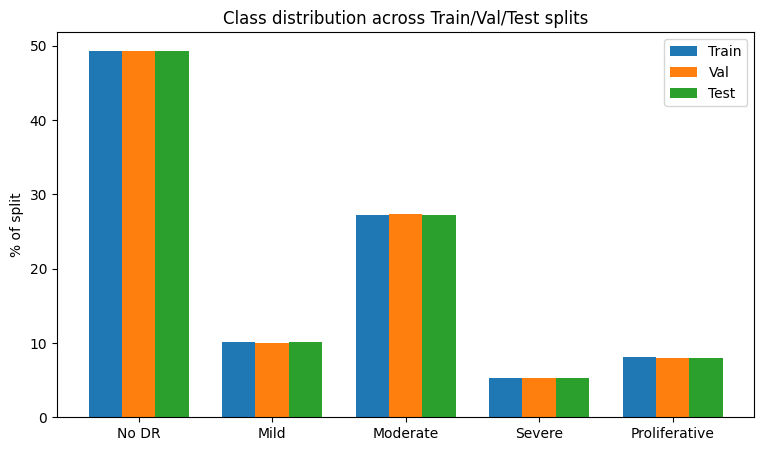

In [12]:
# Visual check — bar chart comparing class % across the three splits
import numpy as np

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(5)
width = 0.25

for i, (name, part) in enumerate([("Train", train_df), ("Val", val_df), ("Test", test_df)]):
    dist = part["diagnosis"].value_counts(normalize=True).sort_index() * 100
    ax.bar(x + i * width, dist.values, width, label=name)

ax.set_xticks(x + width)
ax.set_xticklabels([LABELS[i] for i in range(5)])
ax.set_ylabel("% of split")
ax.set_title("Class distribution across Train/Val/Test splits")
ax.legend()
plt.savefig("split_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# Cell: preprocessing functions
import cv2
import numpy as np

IMG_SIZE = 224

def crop_black_border(img, tol=7):
    """Remove the black background around the circular retina."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if mask.sum() == 0:  # image is all black, skip cropping
        return img
    coords = np.argwhere(mask)
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    return img[y0:y1, x0:x1]

def ben_graham_preprocess(img, sigma=10):
    """Ben Graham's method: subtract local average color to highlight lesions."""
    blurred = cv2.GaussianBlur(img, (0, 0), sigma)
    result = cv2.addWeighted(img, 4, blurred, -4, 128)
    return result

def clahe_preprocess(img):
    """Alternative: CLAHE contrast enhancement on the green channel."""
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def preprocess_image(path, method="ben_graham", size=IMG_SIZE):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = crop_black_border(img)
    img = cv2.resize(img, (size, size))
    if method == "ben_graham":
        img = ben_graham_preprocess(img)
    elif method == "clahe":
        img = clahe_preprocess(img)
    return img

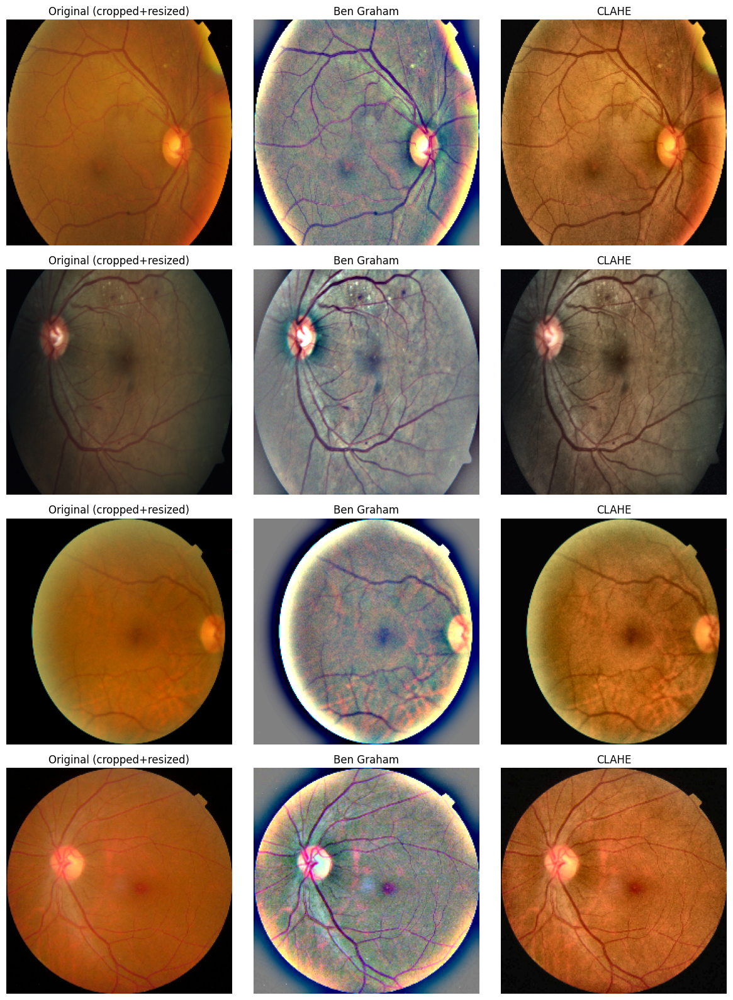

In [14]:
# Cell: before/after comparison — pick a few sample images, show original vs both methods
sample_ids = df.sample(4, random_state=1)["id_code"].tolist()

fig, axes = plt.subplots(4, 3, figsize=(12, 16))
for i, id_code in enumerate(sample_ids):
    path = os.path.join(IMG_DIR, id_code + ".png")
    original = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    original = cv2.resize(crop_black_border(original), (IMG_SIZE, IMG_SIZE))
    bg = preprocess_image(path, method="ben_graham")
    cl = preprocess_image(path, method="clahe")

    axes[i, 0].imshow(original); axes[i, 0].set_title("Original (cropped+resized)"); axes[i, 0].axis("off")
    axes[i, 1].imshow(bg); axes[i, 1].set_title("Ben Graham"); axes[i, 1].axis("off")
    axes[i, 2].imshow(cl); axes[i, 2].set_title("CLAHE"); axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig("preprocessing_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# Cell: apply preprocessing with a visible progress bar
from tqdm.notebook import tqdm

def build_dataset(dataframe, img_dir, method="ben_graham", size=IMG_SIZE):
    X, y = [], []
    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        path = os.path.join(img_dir, row["id_code"] + ".png")
        img = preprocess_image(path, method=method, size=size)
        X.append(img)
        y.append(row["diagnosis"])
    return np.array(X, dtype=np.uint8), np.array(y)

X_train, y_train = build_dataset(train_df, IMG_DIR)
print("Train done:", X_train.shape)

X_val, y_val = build_dataset(val_df, IMG_DIR)
print("Val done:", X_val.shape)

X_test, y_test = build_dataset(test_df, IMG_DIR)
print("Test done:", X_test.shape)

  0%|          | 0/2563 [00:00<?, ?it/s]

Train done: (2563, 224, 224, 3)


  0%|          | 0/549 [00:00<?, ?it/s]

Val done: (549, 224, 224, 3)


  0%|          | 0/550 [00:00<?, ?it/s]

Test done: (550, 224, 224, 3)


In [16]:
# Cell: class weights to handle imbalance (used during training, not by resampling images)
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
print(class_weights)

{np.int64(0): np.float64(0.4058590657165479), np.int64(1): np.float64(1.9791505791505792), np.int64(2): np.float64(0.7333333333333333), np.int64(3): np.float64(3.797037037037037), np.int64(4): np.float64(2.476328502415459)}


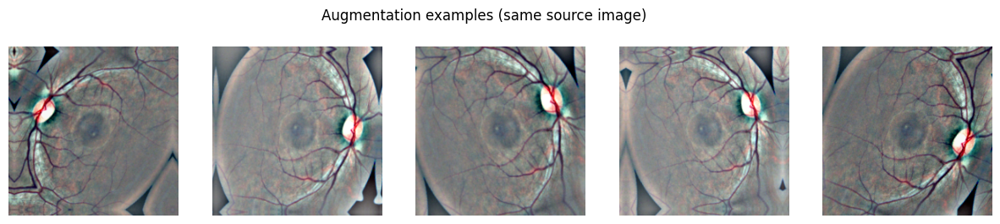

In [18]:
# Cell: augmentation pipeline — applied ONLY to training data, only during training
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

# quick visual check of augmentation
sample_img = X_train[0:1].astype("float32")
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    aug_img = data_augmentation(sample_img, training=True)[0].numpy().astype("uint8")
    axes[i].imshow(aug_img)
    axes[i].axis("off")
plt.suptitle("Augmentation examples (same source image)")
plt.savefig("augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Cell: build tf.data pipelines — normalizes, applies augmentation to train only, batches
BATCH_SIZE = 32

def make_dataset(X, y, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, augment=True, shuffle=True)
val_ds = make_dataset(X_val, y_val, augment=False, shuffle=False)
test_ds = make_dataset(X_test, y_test, augment=False, shuffle=False)

print("Datasets ready.")

Datasets ready.


In [20]:
# Cell: build the model
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

NUM_CLASSES = 5

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False  # freeze for phase 1

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [22]:
# Cell: callbacks — training strategy marks (early stopping, LR scheduling, checkpointing)
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_phase1.keras", monitor="val_loss", save_best_only=True
    ),
]

In [23]:
import tensorflow as tf
print("GPUs available:", tf.config.list_physical_devices('GPU'))

GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [25]:
def make_dataset(X, y, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y),  # cast only, no /255
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# rebuild the datasets with the fix
train_ds = make_dataset(X_train, y_train, augment=True, shuffle=True)
val_ds = make_dataset(X_val, y_val, augment=False, shuffle=False)
test_ds = make_dataset(X_test, y_test, augment=False, shuffle=False)

In [26]:
from tensorflow.keras.applications.efficientnet import preprocess_input

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = preprocess_input(inputs)  # handles EfficientNet-specific scaling
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
# Cell: sanity check — confirm everything is built correctly
print("Train dataset:", train_ds)
model.summary()

Train dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [30]:
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.7015 - loss: 0.9382 - val_accuracy: 0.6721 - val_loss: 0.7298 - learning_rate: 5.0000e-04
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 157ms/step - accuracy: 0.7175 - loss: 0.9167 - val_accuracy: 0.6721 - val_loss: 0.7363 - learning_rate: 5.0000e-04
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 156ms/step - accuracy: 0.7121 - loss: 0.9219 - val_accuracy: 0.6867 - val_loss: 0.7382 - learning_rate: 5.0000e-04
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 160ms/step - accuracy: 0.7284 - loss: 0.8881 - val_accuracy: 0.7013 - val_loss: 0.7129 - learning_rate: 2.5000e-04
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 162ms/step - accuracy: 0.7308 - loss: 0.8839 - val_accuracy: 0.6922 - val_loss: 0.6973 - learning_rate: 2.5000e-04


In [31]:
# Cell: unfreeze the top layers of EfficientNet for fine-tuning
base_model.trainable = True

# Freeze all layers except the last ~30 (fine-tune only the higher-level features)
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Base model has {len(base_model.layers)} layers, fine-tuning from layer {fine_tune_at} onward")
print(f"Trainable layers: {sum(l.trainable for l in base_model.layers)}")

Base model has 238 layers, fine-tuning from layer 208 onward
Trainable layers: 30


In [32]:
# Cell: recompile with a much lower learning rate (critical for fine-tuning)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()  # check trainable param count increased

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 1,660,773 (6.34 MB)

 Non-trainable params: 2,553,411 (9.74 MB)

In [34]:
# Cell: new callbacks for phase 2 (separate checkpoint file so phase 1's best model isn't overwritten)
callbacks_phase2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_phase2.keras", monitor="val_loss", save_best_only=True
    ),
]

In [35]:
# Cell: Phase 2 training — fine-tune
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks_phase2,
    verbose=1
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 68s 474ms/step - accuracy: 0.5154 - loss: 1.3199 - val_accuracy: 0.6539 - val_loss: 0.7789 - learning_rate: 1.0000e-05
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 160ms/step - accuracy: 0.5841 - loss: 1.2023 - val_accuracy: 0.6503 - val_loss: 0.8138 - learning_rate: 1.0000e-05
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 161ms/step - accuracy: 0.6250 - loss: 1.1351 - val_accuracy: 0.6503 - val_loss: 0.8294 - learning_rate: 1.0000e-05
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 160ms/step - accuracy: 0.6348 - loss: 1.0810 - val_accuracy: 0.6576 - val_loss: 0.8201 - learning_rate: 1.0000e-05
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 161ms/step - accuracy: 0.6555 - loss: 1.0550 - val_accuracy: 0.6648 - val_loss: 0.8156 - learning_rate: 5.0000e-06
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 161ms/step - accuracy: 0.6461 - loss: 1.0846 - val_accuracy: 0.6612 - val_loss: 0.8105 - learning_rate: 5.0000e-06


In [36]:
best_val_loss_phase2 = min(history2.history["val_loss"])
best_val_acc_phase2 = max(history2.history["val_accuracy"])
print("Phase 2 best val_loss:", best_val_loss_phase2)
print("Phase 2 best val_accuracy:", best_val_acc_phase2)

Phase 2 best val_loss: 0.7788698673248291
Phase 2 best val_accuracy: 0.6648451685905457


In [39]:
# Reset: reload Phase 1's best weights before trying a gentler fine-tune
model.load_weights("best_model_phase1.keras")

# Unfreeze only the last 10 layers this time (gentler)
base_model.trainable = True
fine_tune_at = len(base_model.layers) - 10
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-6),  # even lower
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_phase2b = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-8),
    tf.keras.callbacks.ModelCheckpoint("best_model_phase2b.keras", monitor="val_loss", save_best_only=True),
]

history2b = model.fit(
    train_ds, validation_data=val_ds, epochs=15,
    class_weight=class_weights, callbacks=callbacks_phase2b, verbose=1
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 60s 432ms/step - accuracy: 0.5923 - loss: 1.2348 - val_accuracy: 0.6958 - val_loss: 0.7308 - learning_rate: 1.0000e-06
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 157ms/step - accuracy: 0.5977 - loss: 1.2288 - val_accuracy: 0.6758 - val_loss: 0.7724 - learning_rate: 1.0000e-06
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.5923 - loss: 1.2132 - val_accuracy: 0.6667 - val_loss: 0.7984 - learning_rate: 1.0000e-06
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 161ms/step - accuracy: 0.6079 - loss: 1.2274 - val_accuracy: 0.6612 - val_loss: 0.8090 - learning_rate: 1.0000e-06
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 158ms/step - accuracy: 0.6094 - loss: 1.2087 - val_accuracy: 0.6612 - val_loss: 0.8123 - learning_rate: 5.0000e-07
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step - accuracy: 0.6075 - loss: 1.2062 - val_accuracy: 0.6576 - val_loss: 0.8138 - learning_rate: 5.0000e-07


In [40]:
# once training stops (early stopping should trigger shortly), compare all three
print("Phase 1 best val_loss:", min(history1.history["val_loss"]),
      " val_accuracy:", max(history1.history["val_accuracy"]))
print("Phase 2 best val_loss:", min(history2.history["val_loss"]),
      " val_accuracy:", max(history2.history["val_accuracy"]))
print("Phase 2b best val_loss:", min(history2b.history["val_loss"]),
      " val_accuracy:", max(history2b.history["val_accuracy"]))

Phase 1 best val_loss: 0.69727623462677  val_accuracy: 0.7012750506401062
Phase 2 best val_loss: 0.7788698673248291  val_accuracy: 0.6648451685905457
Phase 2b best val_loss: 0.7308244705200195  val_accuracy: 0.6958105564117432


In [41]:
# Load the best-performing checkpoint as your final model — Phase 1
model.load_weights("best_model_phase1.keras")
print("Loaded Phase 1 weights as final model.")

Loaded Phase 1 weights as final model.


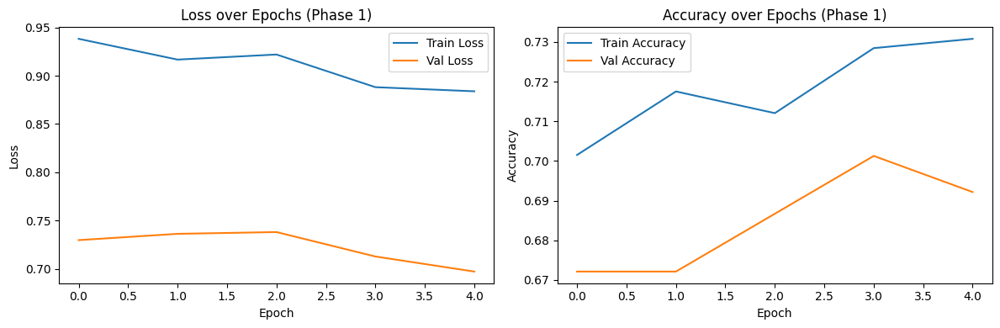

In [42]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history1.history["loss"], label="Train Loss")
plt.plot(history1.history["val_loss"], label="Val Loss")
plt.title("Loss over Epochs (Phase 1)"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history1.history["accuracy"], label="Train Accuracy")
plt.plot(history1.history["val_accuracy"], label="Val Accuracy")
plt.title("Accuracy over Epochs (Phase 1)"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [76]:
# Cell: get predictions on the test set
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

print("Predictions shape:", y_pred_probs.shape)
print("Sample predictions:", y_pred[:10])
print("Sample true labels:", y_test[:10])

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step
Predictions shape: (550, 5)
Sample predictions: [2 2 1 1 0 0 2 0 4 0]
Sample true labels: [2 2 1 2 0 0 2 0 4 0]


In [51]:
# Cell: overall accuracy, precision, recall, F1 (weighted + per-class)
from sklearn.metrics import classification_report, accuracy_score

test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy:.4f}\n")

print(classification_report(
    y_test, y_pred,
    target_names=[LABELS[i] for i in range(5)],
    digits=4
))
 

Test Accuracy: 0.7291

               precision    recall  f1-score   support

        No DR     0.9458    0.9668    0.9562       271
         Mild     0.4615    0.4286    0.4444        56
     Moderate     0.6641    0.5667    0.6115       150
       Severe     0.2400    0.6207    0.3462        29
Proliferative     0.6667    0.2727    0.3871        44

     accuracy                         0.7291       550
    macro avg     0.5956    0.5711    0.5491       550
 weighted avg     0.7601    0.7291    0.7324       550



In [44]:
# Cell: quadratic weighted kappa — standard metric for this dataset (ordinal staging)
from sklearn.metrics import cohen_kappa_score

qwk = cohen_kappa_score(y_test, y_pred, weights="quadratic")
print(f"Quadratic Weighted Kappa: {qwk:.4f}")

Quadratic Weighted Kappa: 0.8450


In [45]:
# Cell: overall accuracy, precision, recall, F1
from sklearn.metrics import classification_report, accuracy_score

test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy:.4f}\n")

print(classification_report(
    y_test, y_pred,
    target_names=[LABELS[i] for i in range(5)],
    digits=4
))

Test Accuracy: 0.7527

               precision    recall  f1-score   support

        No DR     0.9567    0.9779    0.9672       271
         Mild     0.5167    0.5536    0.5345        56
     Moderate     0.7227    0.5733    0.6394       150
       Severe     0.3889    0.2414    0.2979        29
Proliferative     0.3289    0.5682    0.4167        44

     accuracy                         0.7527       550
    macro avg     0.5828    0.5829    0.5711       550
 weighted avg     0.7679    0.7527    0.7544       550



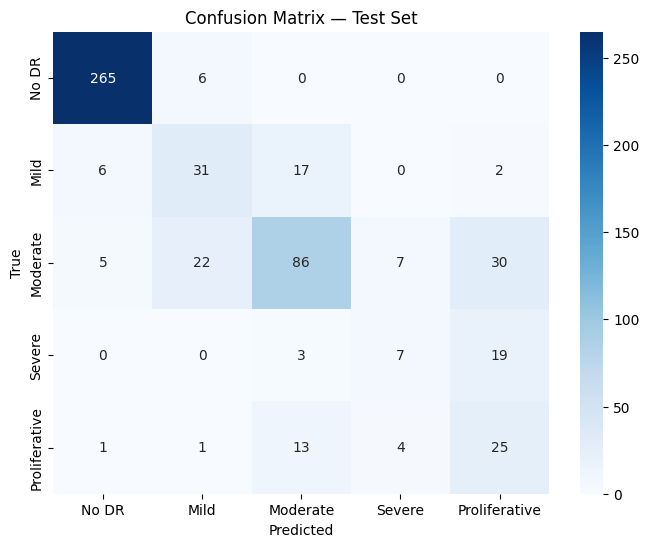

In [46]:
# Cell: confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[LABELS[i] for i in range(5)],
            yticklabels=[LABELS[i] for i in range(5)])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Test Set")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [47]:
# Cell: quadratic weighted kappa
from sklearn.metrics import cohen_kappa_score

qwk = cohen_kappa_score(y_test, y_pred, weights="quadratic")
print(f"Quadratic Weighted Kappa: {qwk:.4f}")

Quadratic Weighted Kappa: 0.8450


136 misclassified out of 550 (24.7%)


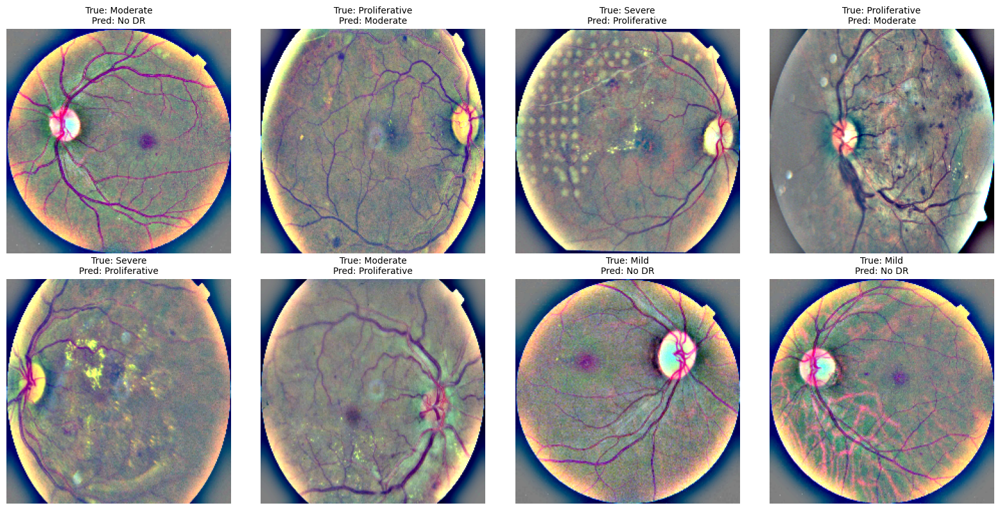

In [48]:
# Cell: find misclassified samples and visualize a sample of them
misclassified_idx = np.where(y_pred != y_test)[0]
print(f"{len(misclassified_idx)} misclassified out of {len(y_test)} ({len(misclassified_idx)/len(y_test)*100:.1f}%)")

# sample 8 misclassifications to display
sample_idx = np.random.RandomState(42).choice(misclassified_idx, size=min(8, len(misclassified_idx)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, idx in enumerate(sample_idx):
    row, col = i // 4, i % 4
    axes[row, col].imshow(X_test[idx])
    true_label = LABELS[y_test[idx]]
    pred_label = LABELS[y_pred[idx]]
    axes[row, col].set_title(f"True: {true_label}\nPred: {pred_label}", fontsize=10)
    axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("misclassified_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
# Cell: which classes get confused with which (from the confusion matrix directly)
print("Most common confusions (true -> predicted):")
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)  # zero out correct predictions
for true_cls in range(5):
    pred_cls = np.argmax(cm_no_diag[true_cls])
    count = cm_no_diag[true_cls, pred_cls]
    if count > 0:
        print(f"  {LABELS[true_cls]} -> misclassified as {LABELS[pred_cls]}: {count} times")

Most common confusions (true -> predicted):
  No DR -> misclassified as Mild: 6 times
  Mild -> misclassified as Moderate: 17 times
  Moderate -> misclassified as Proliferative: 30 times
  Severe -> misclassified as Proliferative: 19 times
  Proliferative -> misclassified as Moderate: 13 times


In [50]:
# Cell: Grad-CAM implementation
import tensorflow as tf

def make_gradcam_heatmap(img_array, model, last_conv_layer_name="top_conv"):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)

# find the base model's last conv layer name
for layer in base_model.layers[::-1]:
    if "conv" in layer.name.lower():
        print("Last conv layer:", layer.name)
        break

Last conv layer: top_conv


In [51]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="top_conv"):
    last_conv_layer = base_model.get_layer(last_conv_layer_name)
    grad_model = tf.keras.models.Model(
        [base_model.inputs], [last_conv_layer.output, base_model.output]
    )
    head_layers = [l for l in model.layers if l.name != "efficientnetb0" and "input" not in l.name]

    with tf.GradientTape() as tape:
        conv_outputs, base_features = grad_model(img_array)
        x = base_features
        for layer in head_layers:
            x = layer(x, training=False)
        predictions = x
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)


def display_gradcam(img_array, heatmap, alpha=0.4):
    heatmap = cv2.resize(heatmap, (img_array.shape[1], img_array.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img_array.astype("uint8"), 1 - alpha, heatmap_color, alpha, 0)
    return overlay

In [55]:
import cv2

def display_gradcam(img_array, heatmap, alpha=0.4):
    heatmap = cv2.resize(heatmap, (img_array.shape[1], img_array.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img_array.astype("uint8"), 1 - alpha, heatmap_color, alpha, 0)
    return overlay

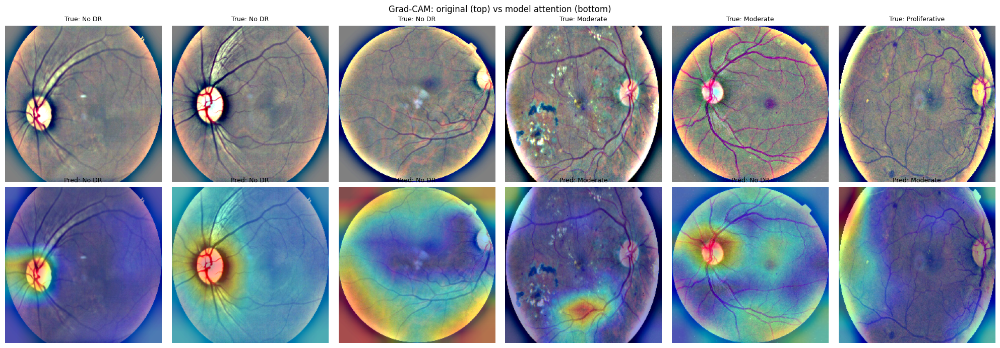

In [57]:
correct_idx = np.where(y_pred == y_test)[0]
sample_correct = np.random.RandomState(1).choice(correct_idx, size=4, replace=False)
sample_wrong = sample_idx[:2]
gradcam_samples = np.concatenate([sample_correct, sample_wrong])

fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for i, idx in enumerate(gradcam_samples):
    img = X_test[idx]
    img_batch = np.expand_dims(img.astype("float32"), axis=0)
    heatmap, pred_class = make_gradcam_heatmap(img_batch, model, "top_conv")
    overlay = display_gradcam(img, heatmap)

    axes[0, i].imshow(img); axes[0, i].axis("off")
    axes[0, i].set_title(f"True: {LABELS[y_test[idx]]}", fontsize=9)
    axes[1, i].imshow(overlay); axes[1, i].axis("off")
    axes[1, i].set_title(f"Pred: {LABELS[pred_class]}", fontsize=9)

plt.suptitle("Grad-CAM: original (top) vs model attention (bottom)")
plt.tight_layout()
plt.savefig("gradcam_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [58]:
# Cell: fixed Grad-CAM function that reaches into the nested EfficientNet layer
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="top_conv"):
    # base_model is the EfficientNetB0 sub-model nested inside `model`
    last_conv_layer = base_model.get_layer(last_conv_layer_name)

    # build a model: same inputs as base_model, outputs = (last conv layer, base_model's final output)
    grad_model = tf.keras.models.Model(
        [base_model.inputs], [last_conv_layer.output, base_model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_features = grad_model(img_array)
        # run the rest of the model (pooling, dropout, dense layers) manually on base_features
        x = model.get_layer("global_average_pooling2d_3")(base_features)
        x = model.get_layer("dropout_6")(x, training=False)
        x = model.get_layer("dense_6")(x)
        x = model.get_layer("dropout_7")(x, training=False)
        predictions = model.get_layer("dense_7")(x)

        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)

In [59]:
print([layer.name for layer in model.layers])

['input_layer_4', 'efficientnetb0', 'global_average_pooling2d_1', 'dropout_2', 'dense_2', 'dropout_3', 'dense_3']


In [76]:
print("IMG_SIZ E:", IMG_SIZE)
print("X_test single image shape:", X_test[0].shape)

IMG_SIZ E: 224
X_test single image shape: (224, 224, 3)


In [62]:
!pip install -q gradio

In [63]:
import gradio as gr

def predict_dr_stage(input_image):
    img = np.array(input_image)
    img = crop_black_border(img)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = ben_graham_preprocess(img)

    img_batch = np.expand_dims(img.astype("float32"), axis=0)
    probs = model.predict(img_batch, verbose=0)[0]
    pred_class = int(np.argmax(probs))

    heatmap, _ = make_gradcam_heatmap(img_batch, model, "top_conv")
    overlay = display_gradcam(img, heatmap)

    confidence_dict = {LABELS[i]: float(probs[i]) for i in range(5)}
    return f"{LABELS[pred_class]} (Stage {pred_class})", confidence_dict, overlay

In [69]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="top_conv"):
    last_conv_layer = base_model.get_layer(last_conv_layer_name)
    grad_model = tf.keras.models.Model(
        [base_model.inputs], [last_conv_layer.output, base_model.output]
    )
    head_layers = [l for l in model.layers if l.name != "efficientnetb0" and "input" not in l.name]

    with tf.GradientTape() as tape:
        conv_outputs, base_features = grad_model(img_array)
        x = base_features
        for layer in head_layers:
            x = layer(x, training=False)
        predictions = x
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)

print("Grad-CAM function loaded:", make_gradcam_heatmap.__code__.co_filename, make_gradcam_heatmap.__code__.co_firstlineno)

Grad-CAM function loaded: /tmp/ipykernel_58/1779852792.py 1


In [80]:
test_path = os.path.join(IMG_DIR, test_df.iloc[0]["id_code"] + ".png")
from PIL import Image
img_pil = Image.open(test_path).convert("RGB")
result = predict_dr_stage(img_pil)
print(result[0])

Moderate (Stage 2)


In [ ]:
demo = gr.Interface(
    fn=predict_dr_stage,
    inputs=gr.Image(type="numpy", label="Upload a retinal fundus image"),
    outputs=[
        gr.Textbox(label="Predicted DR Stage"),
        gr.Label(label="Confidence per class"),
        gr.Image(label="Grad-CAM: model attention"),
    ],
    title="Diabetic Retinopathy Stage Detection",
    description="Upload a retinal fundus image to predict the DR stage (0=No DR to 4=Proliferative), with a Grad-CAM heatmap showing what the model focused on."
)

demo.launch(share=True, debug=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://3b807f3cf438c0b938.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 421, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 56, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1159, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/error

In [91]:
import shutil

os.makedirs("/kaggle/working/demo_images", exist_ok=True)

for cls in range(5):
    row = test_df[test_df["diagnosis"] == cls].iloc[0]
    src = os.path.join(IMG_DIR, row["id_code"] + ".png")
    dst = f"/kaggle/working/demo_images/stage{cls}_{LABELS[cls]}.png"
    shutil.copy(src, dst)
    print(f"Stage {cls} ({LABELS[cls]}): {dst}")

shutil.make_archive("/kaggle/working/demo_images", "zip", "/kaggle/working/demo_images")
print("\nSaved demo_images.zip")

Stage 0 (No DR): /kaggle/working/demo_images/stage0_No DR.png
Stage 1 (Mild): /kaggle/working/demo_images/stage1_Mild.png
Stage 2 (Moderate): /kaggle/working/demo_images/stage2_Moderate.png
Stage 3 (Severe): /kaggle/working/demo_images/stage3_Severe.png
Stage 4 (Proliferative): /kaggle/working/demo_images/stage4_Proliferative.png

Saved demo_images.zip


In [92]:
from IPython.display import FileLink
FileLink("/kaggle/working/demo_images.zip")

/kaggle/working/demo_images.zip


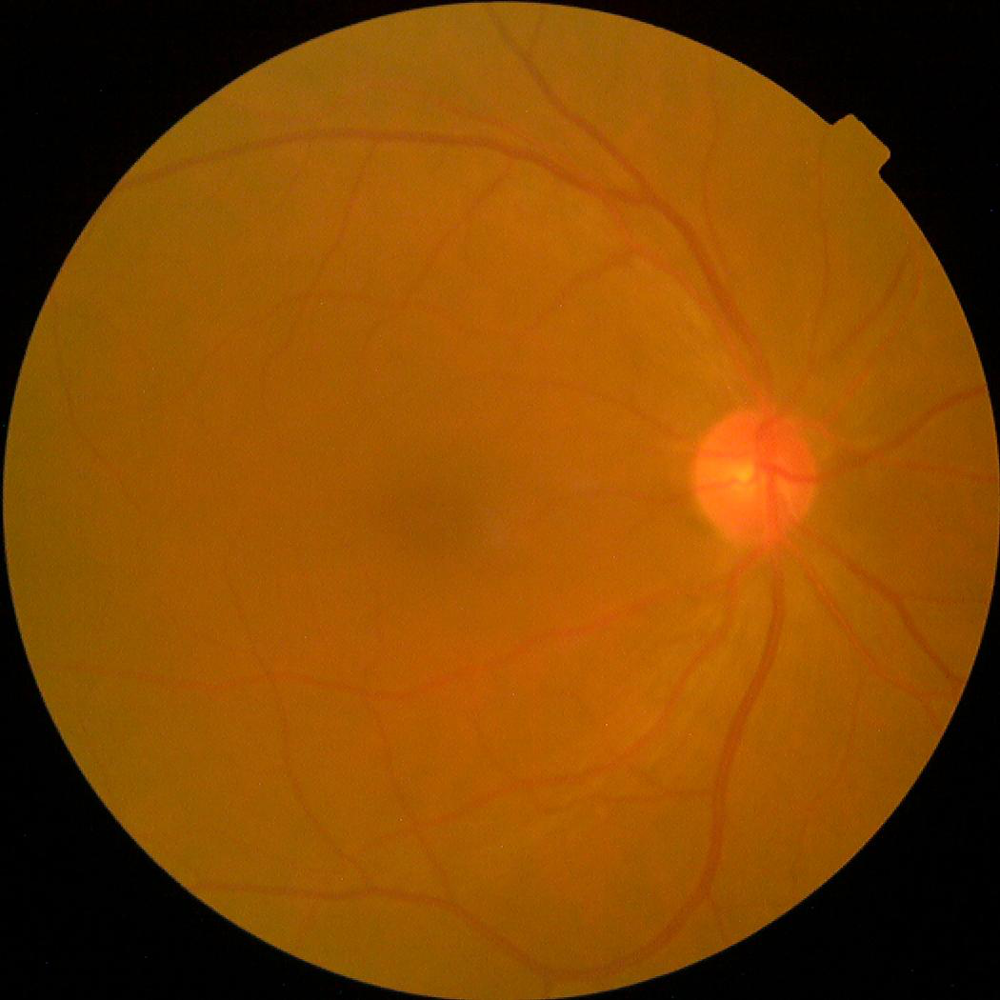


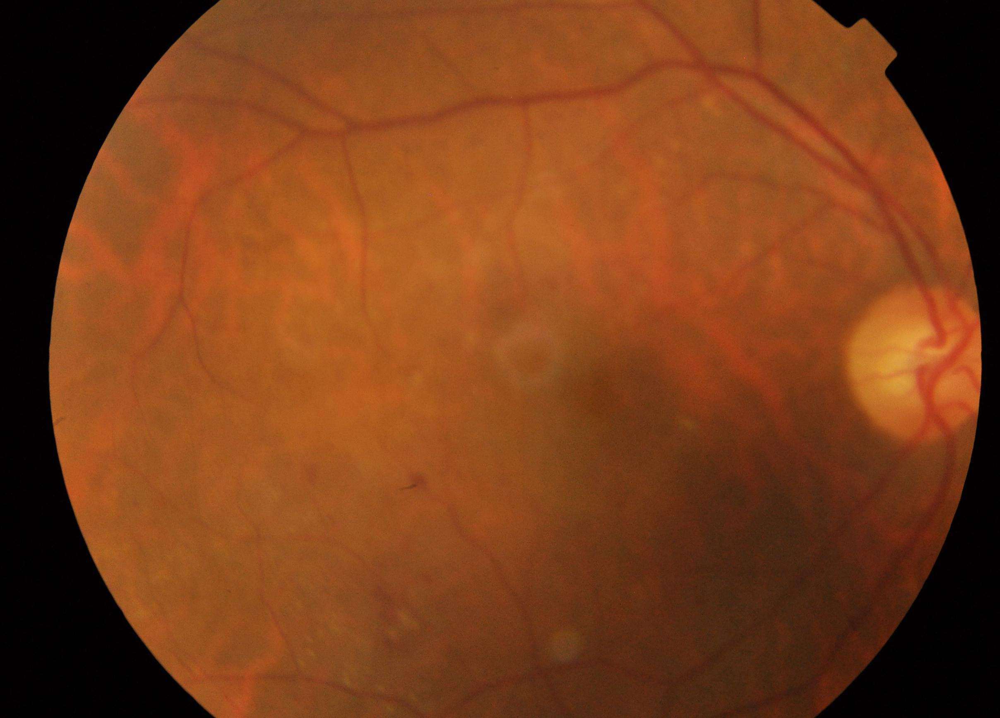


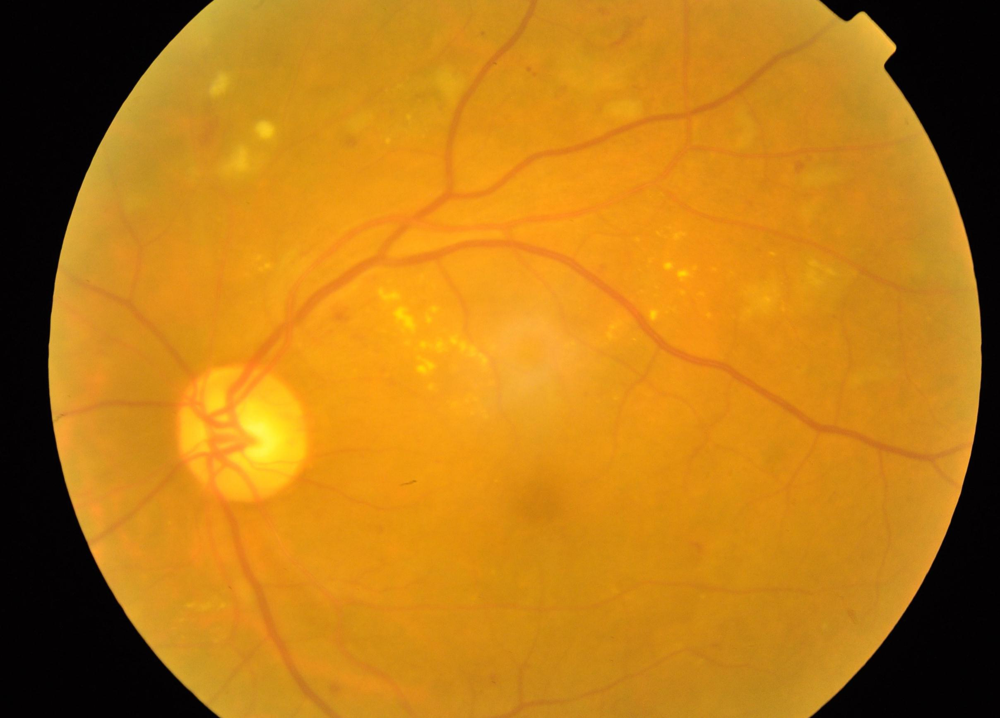


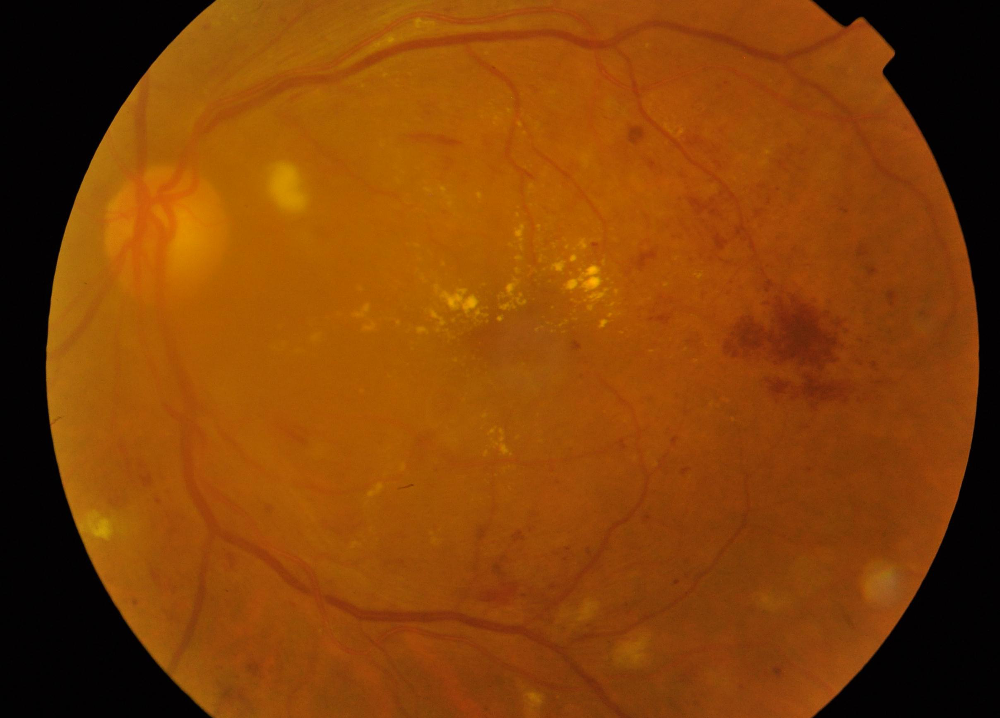


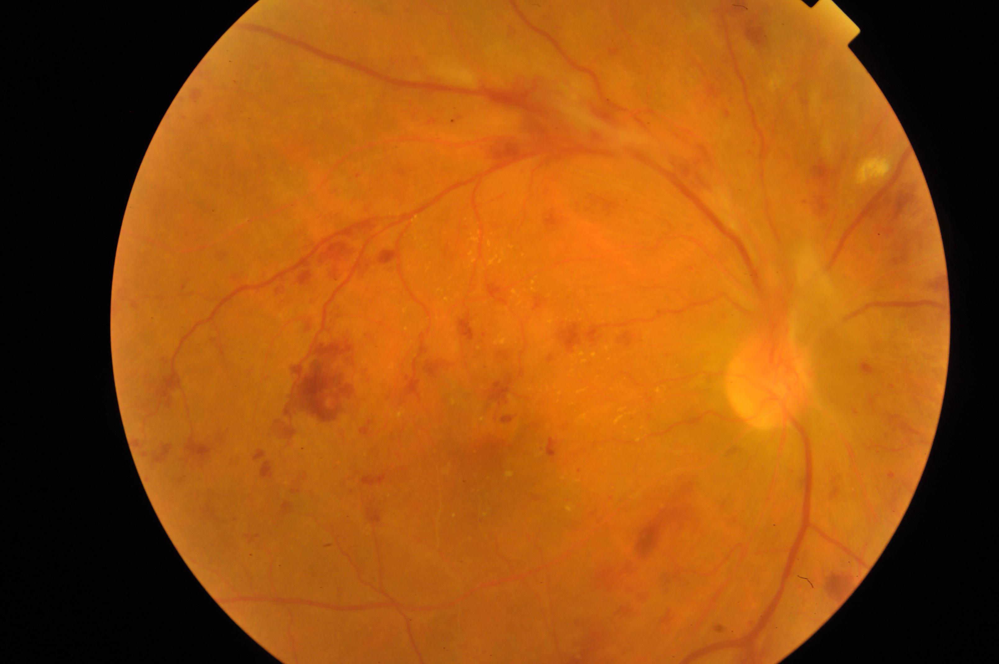

In [93]:
import base64
from IPython.display import HTML, display

for f in sorted(os.listdir("/kaggle/working/demo_images")):
    path = f"/kaggle/working/demo_images/{f}"
    with open(path, "rb") as file:
        b64 = base64.b64encode(file.read()).decode()
    display(HTML(f'<a download="{f}" href="data:image/png;base64,{b64}">⬇ Download {f}</a>'))